In [ ]:
# TASK 1
import pandas as pd

def kulczynski(frequent_itemsets: pd.DataFrame,
               antecedent: frozenset,
               consequent: frozenset) -> float:
    """
    frequent_itemsets: DataFrame with columns ['itemsets', 'support'],
                       where 'itemsets' holds frozensets of items and
                       'support' is relative support in (0,1].
    antecedent, consequent: frozenset of items.
    Returns Kulczynski(A,B) = 0.5 * (P(B|A) + P(A|B)).
    """

    both = antecedent | consequent

    def get_support(items: frozenset) -> float:
        row = frequent_itemsets[frequent_itemsets['itemsets'] == items]
        if row.empty:
            raise ValueError(f"No support found for itemset {items}")
        return float(row['support'].iloc[0])

    supp_a = get_support(antecedent)
    supp_b = get_support(consequent)
    supp_ab = get_support(both)

    p_b_given_a = supp_ab / supp_a
    p_a_given_b = supp_ab / supp_b

    return 0.5 * (p_b_given_a + p_a_given_b)


In [ ]:
#TASK 4
import pandas as pd
import numpy as np
from sklearn.svm import OneClassSVM
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

# 1) Load and preprocess
df = pd.read_csv("/stocks.csv", parse_dates=['Date'])
df = df.sort_values('Date')

# percentage changes of closing prices
returns = df[['MSFT', 'F', 'BAC']].pct_change().dropna()
X = returns.values  # shape (n_samples, 3)

# 2) Fit One-Class SVM
clf = OneClassSVM(kernel='rbf', gamma='auto', nu=0.05)  # adjust nu if needed
clf.fit(X)
labels = clf.predict(X)        # +1 inliers, -1 outliers
scores = clf.decision_function(X)

# 3) 3D scatterplot (returns)
fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111, projection='3d')

colors = np.where(labels == 1, 'b', 'r')
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=colors, s=12)

ax.set_xlabel('MSFT return')
ax.set_ylabel('F return')
ax.set_zlabel('BAC return')
plt.title('One-Class SVM outlier detection on stock returns')
plt.tight_layout()
plt.show()

# 4) Histogram and frequencies of labels
unique, counts = np.unique(labels, return_counts=True)
count_dict = dict(zip(unique, counts))
print("Label counts:", count_dict)

plt.figure(figsize=(5, 4))
plt.hist(labels, bins=[-1.5, -0.5, 0.5, 1.5], rwidth=0.8)
plt.xticks([-1, 1], ['outlier', 'inlier'])
plt.xlabel('Label')
plt.ylabel('Frequency')
plt.title('Histogram of One-Class SVM labels')
plt.tight_layout()
plt.show()

# 5) Percentage of outliers
n_out = count_dict.get(-1, 0)
n_total = len(labels)
outlier_percentage = 100 * n_out / n_total
print(f"Outlier percentage: {outlier_percentage:.2f}%")


FileNotFoundError: [Errno 2] No such file or directory: '/stocks.csv'

Explained variance ratio: [0.47129606 0.11025193]


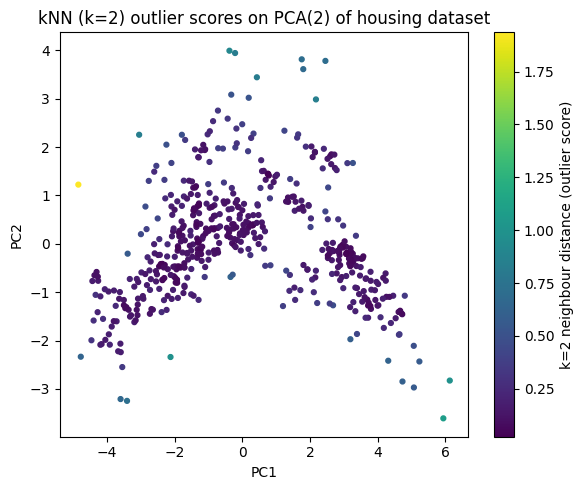

In [ ]:
#TASK 5
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt

# 1) Load Boston housing data from Brownlee repo
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/housing.csv"
hp = pd.read_csv(url, header=None)

# Optional: add column names from housing.names if you want
# names = ['CRIM','ZN','INDUS','CHAS','NOX','RM','AGE','DIS',
#          'RAD','TAX','PTRATIO','B','LSTAT','MEDV']  # [web:64][web:67]
# hp.columns = names

# 2) Select numeric features (all columns except maybe target)
X = hp.iloc[:, :-1].copy()  # use predictors only
X = X.dropna(axis=0)

# 3) Scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4) PCA to 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print("Explained variance ratio:", pca.explained_variance_ratio_)

# 5) kNN outlier score with k=2
k = 2
nn = NearestNeighbors(n_neighbors=k+1)  # include self
nn.fit(X_pca)
distances, indices = nn.kneighbors(X_pca)

outlier_score = distances[:, k]

# 6) Scatterplot coloured by outlier score
plt.figure(figsize=(6, 5))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1],
                      c=outlier_score, cmap='viridis', s=12)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('kNN (k=2) outlier scores on PCA(2) of housing dataset')
cbar = plt.colorbar(scatter)
cbar.set_label('k=2 neighbour distance (outlier score)')
plt.tight_layout()
plt.show()


In [ ]:
#TASK 6
import requests
from bs4 import BeautifulSoup
import pandas as pd

url = "https://dkollias.github.io/Data-Mining-2nd-Assignment/"

resp = requests.get(url)
resp.raise_for_status()

soup = BeautifulSoup(resp.text, "html.parser")
table = soup.find("table")
if table is None:
    raise ValueError("No <table> element found on the page")

header_cells = table.find("tr").find_all(["th", "td"])
columns = [cell.get_text(strip=True) for cell in header_cells]

rows = []
for tr in table.find_all("tr")[1:]:
    cells = tr.find_all("td")
    if not cells:
        continue
    row = [td.get_text(strip=True) for td in cells]
    rows.append(row)

df_income = pd.DataFrame(rows, columns=columns)

def clean_money(x):
    if isinstance(x, str):
        x = x.replace("£", "").replace("$", "").replace(",", "").strip()
    return x

if "Income" in df_income.columns:
    df_income["Income"] = df_income["Income"].map(clean_money)
    df_income["Income"] = pd.to_numeric(df_income["Income"], errors="coerce")

print(df_income.head())
print(df_income.dtypes)


   Region Age   Income Online Shopper
0   India  49  86400.0             No
1  Brazil  32  57600.0            Yes
2     USA  35  64800.0             No
3  Brazil  43  73200.0             No
4     USA  45      NaN            Yes
Region             object
Age                object
Income            float64
Online Shopper     object
dtype: object


In [ ]:
!pip install wikipedia


  Preparing metadata (setup.py) ... done
  Created wheel for wikipedia: filename=wikipedia-1.4.0-py3-none-any.whl size=11678 sha256=5f6bf9d36836369c3661c3210e4bded309f6a995829ce462a4663bac57f9d894
  Stored in directory: /root/.cache/pip/wheels/63/47/7c/a9688349aa74d228ce0a9023229c6c0ac52ca2a40fe87679b8
Successfully built wikipedia


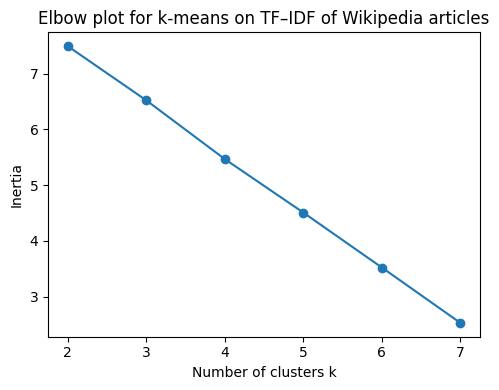

Cluster assignments:
Cluster 1: supervised learning
Cluster 1: unsupervised learning
Cluster 1: semi-supervised learning
Cluster 1: association rule learning
Cluster 2: anomaly detection
Cluster 1: cluster analysis
Cluster 1: dimensionality reduction
Cluster 1: regression analysis
Cluster 1: statistical classification
Cluster 0: data warehouse
Cluster 0: online analytical processing

Top terms per cluster:
Cluster 0: olap, warehouse, rolap, molap, database, operational, business, tables, databases, facts
Cluster 1: displaystyle, training, supervised, regression, function, input, clustering, linear, classification, x_
Cluster 2: anomaly, detection, anomalies, outlier, intrusion, normal, networks, security, video, dynamic


In [ ]:
#TASK 7
import wikipedia
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np

titles_readable = [
    "supervised learning",
    "unsupervised learning",
    "semi-supervised learning",
    "association rule learning",
    "anomaly detection",
    "cluster analysis",
    "dimensionality reduction",
    "regression analysis",
    "statistical classification",
    "data warehouse",
    "online analytical processing",
]

def get_wiki_text_api(title):
    # summary() uses the Wikipedia API, which is less likely to 403
    return wikipedia.page(title).content

docs = [get_wiki_text_api(t) for t in titles_readable]

vectorizer = TfidfVectorizer(stop_words="english", max_df=0.8)
X = vectorizer.fit_transform(docs)

ks = range(2, 8)
inertias = []
for k in ks:
    km = KMeans(n_clusters=k, random_state=0, n_init=10)
    km.fit(X)
    inertias.append(km.inertia_)

plt.figure(figsize=(5, 4))
plt.plot(list(ks), inertias, marker="o")
plt.xlabel("Number of clusters k")
plt.ylabel("Inertia")
plt.title("Elbow plot for k-means on TF–IDF of Wikipedia articles")
plt.tight_layout()
plt.show()

k_opt = 3  # choose after seeing elbow
km_final = KMeans(n_clusters=k_opt, random_state=0, n_init=10)
labels = km_final.fit_predict(X)

print("Cluster assignments:")
for title, label in zip(titles_readable, labels):
    print(f"Cluster {label}: {title}")

terms = np.array(vectorizer.get_feature_names_out())
order_centroids = km_final.cluster_centers_.argsort(axis=1)[:, ::-1]

print("\nTop terms per cluster:")
for i in range(k_opt):
    top_terms = terms[order_centroids[i, :10]]
    print(f"Cluster {i}: {', '.join(top_terms)}")
